# CT Denoising Dataset

## 1. Setup

In [ ]:
!pip install -q scikit-image numpy matplotlib pandas scipy


## 2. Configuration

In [ ]:
import numpy as np
from skimage.draw import disk, ellipse, polygon
from skimage.metrics import peak_signal_noise_ratio as psnr
from scipy.ndimage import binary_erosion
import matplotlib.pyplot as plt
import os, csv, shutil
from PIL import Image

SEED = 42
IMG_SIZE = 256          # 256x256 = sharp images (use 128 for a smaller/faster dataset)
SUPERSAMPLE = 2         # draw at 2x size then shrink -> smooth, anti-aliased edges
N_TRAIN, N_VAL, N_TEST = 4200, 400, 400
N_TOTAL = N_TRAIN + N_VAL + N_TEST
OUT_DIR = "/content/data"
os.makedirs(OUT_DIR, exist_ok=True)

## 3. Shape and phantom generator

In [ ]:
def random_blob_vertices(cr, cc, radius, rng, n_points=48):
    """Irregular smooth 'random figure': radius wobbles with a few random sinusoids."""
    theta = np.linspace(0, 2 * np.pi, n_points, endpoint=False)
    r = np.ones_like(theta)
    for k in range(2, 6):
        r += rng.uniform(0.0, 0.22) / (k - 1) * np.sin(k * theta + rng.uniform(0, 2 * np.pi))
    r = np.clip(r, 0.35, None) * radius
    return cr + r * np.sin(theta), cc + r * np.cos(theta)


def regular_polygon_vertices(cr, cc, radius, n_sides, rotation):
    theta = rotation + np.linspace(0, 2 * np.pi, n_sides, endpoint=False)
    return cr + radius * np.sin(theta), cc + radius * np.cos(theta)


def shape_pixels(kind, cr, cc, radius, rng, shape):
    """Return (rows, cols) pixel indices of one shape of a given kind."""
    if kind == "circle":
        return disk((cr, cc), radius, shape=shape)
    if kind == "ellipse":
        r_r = radius * rng.uniform(0.5, 1.0)
        r_c = radius * rng.uniform(0.5, 1.0)
        return ellipse(cr, cc, max(r_r, 1.5), max(r_c, 1.5), shape=shape,
                       rotation=rng.uniform(0, np.pi))
    if kind == "rectangle":
        half_h = radius * rng.uniform(0.6, 1.0)
        half_w = radius * rng.uniform(0.6, 1.0)
        ang = rng.uniform(0, np.pi)
        corners = np.array([[-half_h, -half_w], [-half_h, half_w],
                            [half_h, half_w], [half_h, -half_w]])
        rot = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
        pts = corners @ rot.T
        return polygon(cr + pts[:, 0], cc + pts[:, 1], shape=shape)
    if kind == "polygon":
        n_sides = int(rng.integers(3, 9))
        vr, vc = regular_polygon_vertices(cr, cc, radius, n_sides, rng.uniform(0, 2 * np.pi))
        return polygon(vr, vc, shape=shape)
    if kind == "blob":
        vr, vc = random_blob_vertices(cr, cc, radius, rng)
        return polygon(vr, vc, shape=shape)
    raise ValueError(kind)


OUTER_KINDS = ["circle", "ellipse", "rectangle", "polygon", "blob"]
FEATURE_KINDS = ["circle", "ellipse", "rectangle", "polygon", "blob"]


def make_industrial_phantom(size, rng):
    """One synthetic industrial CT cross-section with mixed shapes."""
    img = np.zeros((size, size), dtype=np.float32)
    s = size / 128.0  # all pixel-based settings scale with image size

    # ---- outer part: random shape, size, and position ----
    outer_kind = OUTER_KINDS[rng.integers(0, len(OUTER_KINDS))]
    cr = size / 2 + rng.integers(-8, 9) * s
    cc = size / 2 + rng.integers(-8, 9) * s
    outer_size = size * rng.uniform(0.30, 0.46)

    rr, cc_idx = shape_pixels(outer_kind, cr, cc, outer_size, rng, img.shape)
    part_mask = np.zeros(img.shape, dtype=bool)
    part_mask[rr, cc_idx] = True

    base_value = rng.uniform(0.20, 0.65)
    img[part_mask] = base_value

    # ---- bright rim (edge effect) ----
    rim_thickness = max(1, int(round(rng.integers(1, 5) * s)))
    inner = binary_erosion(part_mask, iterations=rim_thickness)
    rim_boost = rng.uniform(0.1, 0.35)
    img[part_mask & ~inner] = min(base_value + rim_boost, 1.0)

    # ---- inclusions: mixed shapes, only drawn inside the part ----
    n_inclusions = int(rng.integers(0, 7))
    for _ in range(n_inclusions):
        kind = FEATURE_KINDS[rng.integers(0, len(FEATURE_KINDS))]
        ys, xs = np.nonzero(inner)
        if len(ys) == 0:
            break
        k = rng.integers(0, len(ys))
        rr, cc2 = shape_pixels(kind, ys[k], xs[k], rng.uniform(5, 18) * s, rng, img.shape)
        keep = inner[rr, cc2]
        img[rr[keep], cc2[keep]] = rng.uniform(0.5, 0.98)

    # ---- pores / voids: mixed shapes, only drawn inside the part ----
    n_pores = int(rng.integers(0, 10))
    for _ in range(n_pores):
        kind = FEATURE_KINDS[rng.integers(0, len(FEATURE_KINDS))]
        ys, xs = np.nonzero(inner)
        if len(ys) == 0:
            break
        k = rng.integers(0, len(ys))
        rr, cc2 = shape_pixels(kind, ys[k], xs[k], rng.uniform(2, 8) * s, rng, img.shape)
        keep = inner[rr, cc2]
        img[rr[keep], cc2[keep]] = rng.uniform(0.0, 0.08)

    return (np.clip(img, 0.0, 1.0).astype(np.float32),
            outer_kind, n_inclusions, n_pores, float(outer_size), float(base_value))


def add_noise(clean_img, photon_count, gaussian_sigma, rng):
    scaled = clean_img * photon_count
    poisson_noisy = rng.poisson(scaled).astype(np.float32) / photon_count
    gaussian_noise = rng.normal(0, gaussian_sigma, clean_img.shape).astype(np.float32)
    return np.clip(poisson_noisy + gaussian_noise, 0.0, 1.0).astype(np.float32)


def dose_class_for(photon_count):
    if photon_count < 1800:
        return "low_dose"
    elif photon_count < 3200:
        return "medium_dose"
    else:
        return "high_dose"


def make_phantom_smooth(size, rng, supersample=2):
    """Draw at `supersample` x resolution, then average down -> smooth, anti-aliased edges."""
    big = size * supersample
    img, kind, n_inc, n_por, outer_size, base_value = make_industrial_phantom(big, rng)
    img = img.reshape(size, supersample, size, supersample).mean(axis=(1, 3))
    return img.astype(np.float32), kind, n_inc, n_por, outer_size / supersample, base_value

## 4. Generating 5000 samples (+ metadata)

In [ ]:
rng = np.random.default_rng(SEED)

clean_images = np.zeros((N_TOTAL, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
noisy_images = np.zeros((N_TOTAL, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
metadata_rows = []

all_idx = np.arange(N_TOTAL)
split_labels = ["train"] * N_TRAIN + ["val"] * N_VAL + ["test"] * N_TEST

for i in range(N_TOTAL):
    clean_f, outer_kind, n_inclusions, n_pores, outer_size, base_value = make_phantom_smooth(IMG_SIZE, rng, SUPERSAMPLE)

    photon_count = int(rng.integers(800, 6000))
    gaussian_sigma = rng.uniform(0.005, 0.02)
    noisy_f = add_noise(clean_f, photon_count, gaussian_sigma, rng)

    clean_images[i] = (clean_f * 255).astype(np.uint8)
    noisy_images[i] = (noisy_f * 255).astype(np.uint8)

    metadata_rows.append({
        "sample_id": f"sample_{i:05d}",
        "split": split_labels[i],
        "outer_shape": outer_kind,
        "dose_class": dose_class_for(photon_count),
        "photon_count": photon_count,
        "gaussian_sigma": round(float(gaussian_sigma), 5),
        "n_inclusions": n_inclusions,
        "n_pores": n_pores,
        "outer_size_px": round(outer_size, 2),
        "base_material_value": round(base_value, 4),
        "psnr_noisy_vs_clean_db": round(float(psnr(clean_f, noisy_f, data_range=1.0)), 3),
    })

idx_train = all_idx[:N_TRAIN]
idx_val = all_idx[N_TRAIN:N_TRAIN + N_VAL]
idx_test = all_idx[N_TRAIN + N_VAL:]

print(f"Generated {N_TOTAL} samples (train={N_TRAIN}, val={N_VAL}, test={N_TEST})")

Generated 5000 samples (train=4200, val=400, test=400)


## 5. Viewing any single image
We can change `INDEX` (0 to 4999) and re-run this cell to view a particular image.

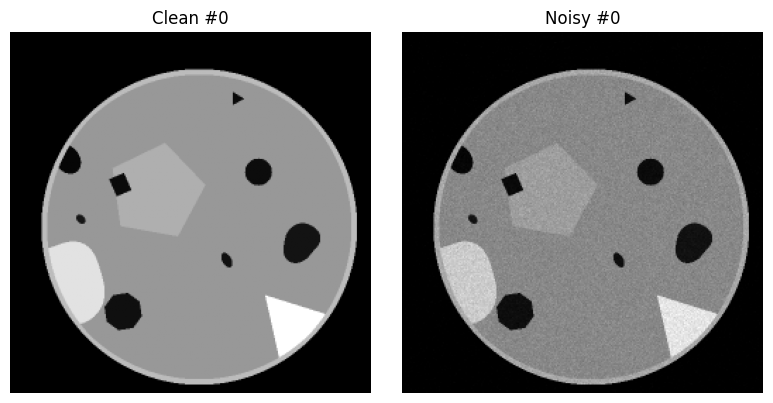

{'sample_id': 'sample_00000', 'split': 'train', 'outer_shape': 'circle', 'dose_class': 'low_dose', 'photon_count': 980, 'gaussian_sigma': 0.00587, 'n_inclusions': 3, 'n_pores': 8, 'outer_size_px': 111.97, 'base_material_value': 0.5138, 'psnr_noisy_vs_clean_db': 34.564}


In [ ]:
INDEX = 0  # <-- change this number and re-run

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(clean_images[INDEX], cmap='gray')
axes[0].set_title(f'Clean #{INDEX}')
axes[0].axis('off')
axes[1].imshow(noisy_images[INDEX], cmap='gray')
axes[1].set_title(f'Noisy #{INDEX}')
axes[1].axis('off')
plt.tight_layout()
plt.show()
print(metadata_rows[INDEX])

## 6. Viewing a grid spread across the dataset

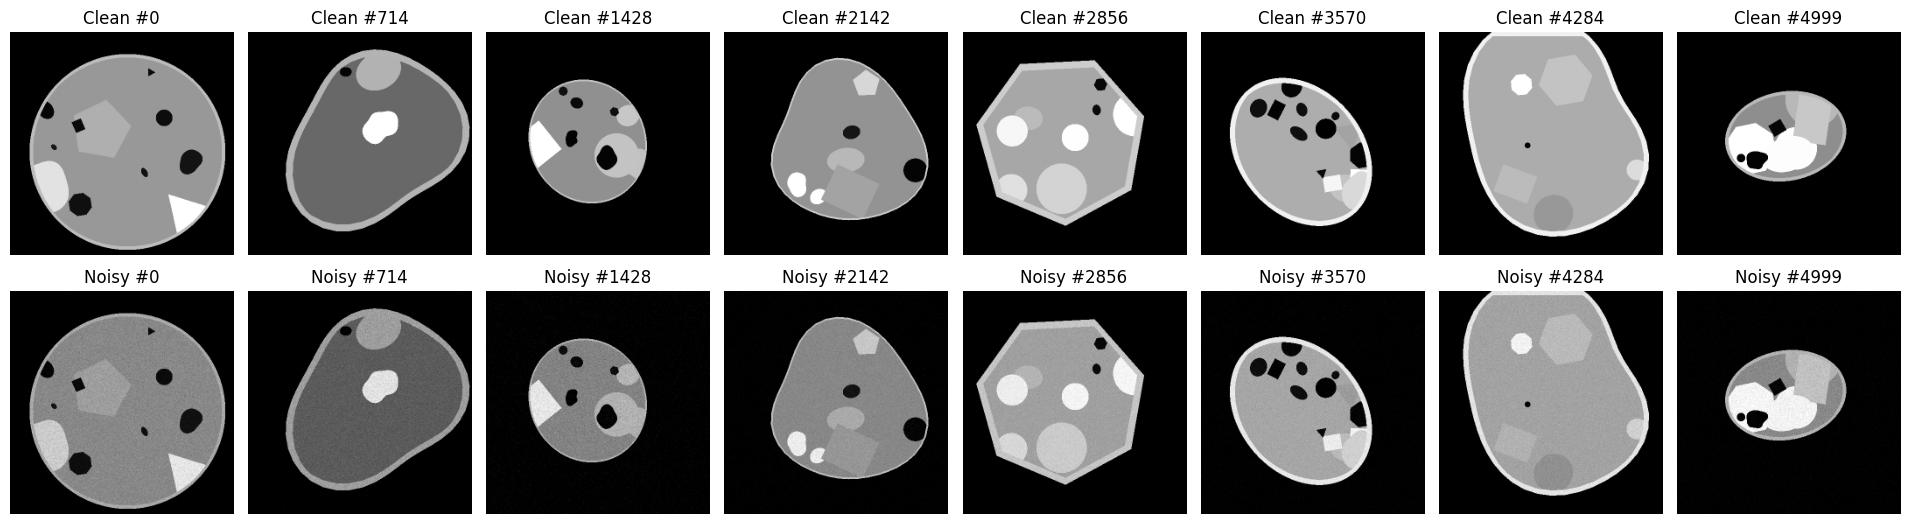

In [ ]:
indices = np.linspace(0, N_TOTAL - 1, 8).astype(int)

fig, axes = plt.subplots(2, len(indices), figsize=(2.4 * len(indices), 5.5))
for col, idx in enumerate(indices):
    axes[0, col].imshow(clean_images[idx], cmap='gray')
    axes[0, col].set_title(f'Clean #{idx}')
    axes[0, col].axis('off')
    axes[1, col].imshow(noisy_images[idx], cmap='gray')
    axes[1, col].set_title(f'Noisy #{idx}')
    axes[1, col].axis('off')
plt.tight_layout()
plt.show()

## 7. Saving the dataset and metadata

In [ ]:
npz_path = os.path.join(OUT_DIR, "ct_denoise_dataset_5000_shapes_256.npz")
np.savez_compressed(
    npz_path,
    clean=clean_images,
    noisy=noisy_images,
    idx_train=idx_train,
    idx_val=idx_val,
    idx_test=idx_test,
)

csv_path = os.path.join(OUT_DIR, "dataset_metadata.csv")
with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(metadata_rows[0].keys()))
    writer.writeheader()
    writer.writerows(metadata_rows)

print(f"Saved: {npz_path} ({os.path.getsize(npz_path)/1024/1024:.2f} MB)")
print(f"Saved: {csv_path}")

Saved: /content/data/ct_denoise_dataset_5000_shapes_256.npz (169.26 MB)
Saved: /content/data/dataset_metadata.csv


## 8. Previewing the metadata table

In [ ]:
import pandas as pd
df = pd.read_csv(csv_path)
print(df['outer_shape'].value_counts())
df.head(10)

outer_shape
rectangle    1019
polygon      1010
ellipse       994
blob          990
circle        987
Name: count, dtype: int64


,sample_id,split,outer_shape,dose_class,photon_count,gaussian_sigma,n_inclusions,n_pores,outer_size_px,base_material_value,psnr_noisy_vs_clean_db
0,sample_00000,train,circle,low_dose,980,0.00587,3,8,111.97,0.5138,34.564
1,sample_00001,train,ellipse,medium_dose,2692,0.00999,4,6,80.41,0.6260,40.309
2,sample_00002,train,circle,low_dose,900,0.01517,6,6,92.72,0.4992,33.762
3,sample_00003,train,blob,high_dose,3679,0.01321,4,4,114.72,0.3404,36.783
4,sample_00004,train,ellipse,high_dose,3949,0.00939,5,3,90.89,0.2144,41.472
5,sample_00005,train,circle,high_dose,4852,0.01636,1,3,88.82,0.3568,36.708
6,sample_00006,train,ellipse,medium_dose,1845,0.01953,4,8,89.72,0.2032,36.008
7,sample_00007,train,circle,high_dose,4890,0.00836,4,7,78.87,0.6059,41.071
8,sample_00008,train,polygon,high_dose,5399,0.01654,0,9,107.72,0.4964,36.644
9,sample_00009,train,ellipse,high_dose,5375,0.01862,2,5,96.37,0.5523,36.310


## 9. Exporting images
```
dataset_png/
  train/clean/*.png   train/noisy/*.png   (4200 each)
  val/clean/*.png     val/noisy/*.png     (400 each)
  test/clean/*.png    test/noisy/*.png    (400 each)
```

In [ ]:
PNG_ROOT = "/content/dataset_png"
if os.path.exists(PNG_ROOT):
    shutil.rmtree(PNG_ROOT)

def save_split_as_png(split_name, indices):
    clean_dir = os.path.join(PNG_ROOT, split_name, "clean")
    noisy_dir = os.path.join(PNG_ROOT, split_name, "noisy")
    os.makedirs(clean_dir, exist_ok=True)
    os.makedirs(noisy_dir, exist_ok=True)
    for idx in indices:
        Image.fromarray(clean_images[idx]).save(os.path.join(clean_dir, f"{idx:05d}.png"))
        Image.fromarray(noisy_images[idx]).save(os.path.join(noisy_dir, f"{idx:05d}.png"))

save_split_as_png("train", idx_train)
save_split_as_png("val", idx_val)
save_split_as_png("test", idx_test)

print("Saved PNGs into /content/dataset_png/{train,val,test}/{clean,noisy}/")

Saved PNGs into /content/dataset_png/{train,val,test}/{clean,noisy}/


## 10. Creating Zips

In [ ]:
shutil.make_archive("/content/train_images", "zip", os.path.join(PNG_ROOT, "train"))
shutil.make_archive("/content/val_images", "zip", os.path.join(PNG_ROOT, "val"))
shutil.make_archive("/content/test_images", "zip", os.path.join(PNG_ROOT, "test"))
print("Zips created: train_images.zip, val_images.zip, test_images.zip")

Zips created: train_images.zip, val_images.zip, test_images.zip


## 11. Downloads

In [ ]:
from google.colab import files
files.download("/content/train_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/val_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/test_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download(npz_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download(csv_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/PHC351_CT_Denoising_Project"
TR, TE = f"{ROOT}/Training_Data", f"{ROOT}/Testing_Data"
os.makedirs(TR, exist_ok=True); os.makedirs(TE, exist_ok=True)

# find your generated files
cands = ["/content/data", "/content"]
d = next(p for p in cands if os.path.exists(f"{p}/ct_denoise_dataset_5000_shapes_256.npz"))
z = np.load(f"{d}/ct_denoise_dataset_5000_shapes_256.npz")
meta = pd.read_csv(f"{d}/dataset_metadata.csv")

clean, noisy = z["clean"], z["noisy"]
itv = np.concatenate([z["idx_train"], z["idx_val"]]); ite = z["idx_test"]
assert clean.shape == (5000, 256, 256) and len(itv) == 4600 and len(ite) == 400
assert itv.max() < ite.min(), "unexpected order"

np.savez_compressed(f"{TR}/train_val_data.npz", clean=clean[itv], noisy=noisy[itv])
np.savez_compressed(f"{TE}/test_data.npz", clean=clean[ite], noisy=noisy[ite])
meta.iloc[itv].to_csv(f"{TR}/dataset_metadata_train_val.csv", index=False)
meta.iloc[ite].to_csv(f"{TE}/dataset_metadata_test.csv", index=False)
print("Done. Saved into", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Done. Saved into /content/drive/MyDrive/PHC351_CT_Denoising_Project
